In [1]:
!cp 2400329s/spec_h_norm.txt .
!cp 2400329s/*npy .

In [2]:
import numpy as np
from petitRADTRANS import Radtrans
import astropy.units as u
import astropy.constants as const

In [53]:
atmosphere = Radtrans(line_species = ['H2O_main_iso',
                                      'CO2_main_iso',
                                      'CH4_Hargreaves_main_iso'],
                      rayleigh_species = ['N2', 'O2'],
                      continuum_opacities = ['N2-N2', 'N2-O2', 'O2-O2'],
                      wlen_bords_micron = [2, 2.014], mode="lbl")

/Users/huihaoz/miniconda3/envs/new_env/lib/python3.9/site-packages/petitRADTRANS/radtrans.py:119: FutureWarning: pRT_input_data_path was set by an environment variable. In a future update, the path to the petitRADTRANS input_data will be set within a .ini file that will be automatically generated into the user home directory (OS agnostic), inside a .petitradtrans directory
  warnings.warn(f"pRT_input_data_path was set by an environment variable. In a future update, the path to "


  Read line opacities of H2O_main_iso...
  Read line opacities of CO2_main_iso...
  Read line opacities of CH4_Hargreaves_main_iso...

  Read CIA opacities for N2-N2...
  Read CIA opacities for N2-O2...
  Read CIA opacities for O2-O2...
Done.



In [54]:
import astropy.io.ascii

In [55]:
pt = np.load("pt_us_avg.npy")

In [56]:
# -6 is about 4.5 km
last_ind = -6

pressures = pt[0][0:last_ind]
atmosphere.setup_opa_structure(pressures)

temperature = pt[1][0:last_ind]

In [57]:
pressures

array([1.00000000e-06, 1.14975700e-06, 1.32194115e-06, 1.51991108e-06,
       1.74752840e-06, 2.00923300e-06, 2.31012970e-06, 2.65608778e-06,
       3.05385551e-06, 3.51119173e-06, 4.03701726e-06, 4.64158883e-06,
       5.33669923e-06, 6.13590727e-06, 7.05480231e-06, 8.11130831e-06,
       9.32603347e-06, 1.07226722e-05, 1.23284674e-05, 1.41747416e-05,
       1.62975083e-05, 1.87381742e-05, 2.15443469e-05, 2.47707636e-05,
       2.84803587e-05, 3.27454916e-05, 3.76493581e-05, 4.32876128e-05,
       4.97702356e-05, 5.72236766e-05, 6.57933225e-05, 7.56463328e-05,
       8.69749003e-05, 1.00000000e-04, 1.14975700e-04, 1.32194115e-04,
       1.51991108e-04, 1.74752840e-04, 2.00923300e-04, 2.31012970e-04,
       2.65608778e-04, 3.05385551e-04, 3.51119173e-04, 4.03701726e-04,
       4.64158883e-04, 5.33669923e-04, 6.13590727e-04, 7.05480231e-04,
       8.11130831e-04, 9.32603347e-04, 1.07226722e-03, 1.23284674e-03,
       1.41747416e-03, 1.62975083e-03, 1.87381742e-03, 2.15443469e-03,
      

In [58]:
import petitRADTRANS.nat_cst as nc
from petitRADTRANS.physics import guillot_global
mass_fractions = {}
mass_fractions['N2'] = 0.781 * np.ones_like(temperature)
mass_fractions['O2'] = 0.209 * np.ones_like(temperature)
mass_fractions['H2O_main_iso'] = 10**(-2.6) * np.ones_like(temperature)
mass_fractions['CO2_main_iso'] = 440e-6 * np.ones_like(temperature)
mass_fractions['CH4_Hargreaves_main_iso'] = 10**(-5.7) * np.ones_like(temperature)


In [59]:
gravity = 980.0
MMW = 29.0 * np.ones_like(temperature)

atmosphere.calc_flux(temperature, mass_fractions, gravity, MMW)


In [60]:
import matplotlib.pylab as plt

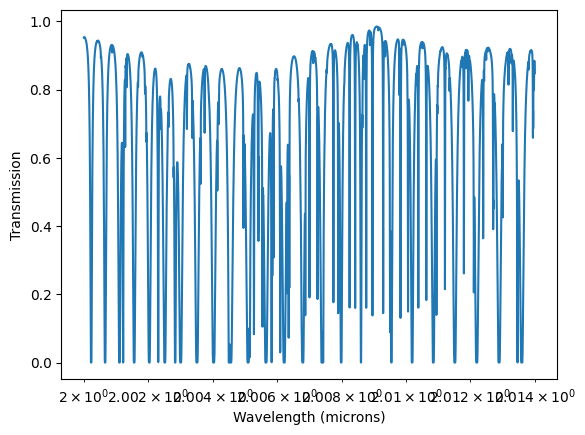

<Figure size 640x480 with 0 Axes>

In [61]:
plt.plot(nc.c/atmosphere.freq/1e-4, np.exp(-atmosphere.total_tau[0,:,0,-1]))

plt.xscale('log')
plt.xlabel('Wavelength (microns)')
plt.ylabel("Transmission")
plt.show()
plt.clf()

In [62]:
import JW_lib

#spec_data = JW_lib.readSpec("spec_h_norm2.txt")

In [63]:
def broadenSpec(spec_input, resolving_power=75e3, pixel_sampling=5.0):
    spec_tmp = spec_input.copy()
    spec_tmp = spec_tmp.spectral_blur(rpower=resolving_power)
    spec_tmp.spec_reso = resolving_power
    spec_tmp = spec_tmp.resampleSpectoSpectrograph(pixel_sampling=pixel_sampling)
    return(spec_tmp)

In [64]:
def getContinuumLowHighValue(spec, low=0.8, high=1.1):
    ind = np.where((spec.flux > high) | (spec.flux < low))
    spec_tmp = spec.copy()
    spec_tmp.flux[ind] = np.median(spec.flux)
    cont = spec_tmp.applyHighPassFilter(pass_type="low", order = 5, cutoff = 1000.0)
    return(cont.flux, spec_tmp.flux)
    
def getContinuumLowHighPercentile(spec, low=0.8, high=0.95):
    per_low = np.percentile(spec.flux, low)
    per_high = np.percentile(spec.flux, high)
    ind = np.where((spec.flux > per_high) | (spec.flux < per_low))
    spec_tmp = spec.copy()
    spec_tmp.flux[ind] = np.median(spec.flux)
    cont = spec_tmp.applyHighPassFilter(pass_type="low", order = 5, cutoff = 1000.0)
    return(cont.flux, spec_tmp.flux)

def norm_spec(spec):
    cont, spec_tmp = getContinuumLowHighValue(spec, low=0.8, high=1.2)
    spec.flux = spec.flux / cont
    cont, spec_tmp = getContinuumLowHighValue(spec, low=0.98, high=1.05)
    spec.flux = spec.flux / cont
    cont, spec_tmp = getContinuumLowHighValue(spec, low=1.0, high=1.02)
    spec.flux = spec.flux / cont
    return(spec)

In [65]:
def calcModel(params, wav_grid=nc.c/atmosphere.freq/1e-4):
    delta_t, delta_p, mr_h2o, mr_co2, mr_ch4, spec_reso, delta_x, air_mass,mr_n2 = \
        params["delta_t"], params["delta_p"], params["mr_h2o"], params["mr_co2"], params["mr_ch4"], \
        params["spec_reso"], params["delta_x"], params["air_mass"],params["mr_n2"]

    atmosphere.setup_opa_structure(pt[0][0:last_ind] + delta_p)
    temperature = pt[1][0:last_ind] + delta_t
    
    MMW = 29.0 * np.ones_like(temperature)
    mass_fractions = {}
    mass_fractions['N2'] = mr_n2 * 28.0 / MMW 
    mass_fractions['O2'] = 0.21 * 32.0 / MMW 
    mass_fractions['H2O_main_iso'] = mr_h2o * 18.0 / MMW 
    mass_fractions['CO2_main_iso'] = mr_co2 * 44.0 / MMW
    mass_fractions['CH4_Hargreaves_main_iso'] = mr_ch4 * 16.0 / MMW
    
    gravity = 980.0

    atmosphere.calc_flux(temperature, mass_fractions, gravity, MMW)
    tau = atmosphere.total_tau[0,:,0,-1]
    wav, flx = nc.c/atmosphere.freq/1e-4, np.exp(-tau * air_mass)
    
    spec = JW_lib.Spectrum(wav, flx)
    spec = broadenSpec(spec, resolving_power=spec_reso)
    
    cont = spec.getContinuum(poly_order=1)
    spec.flux = spec.flux / cont
    
    spec = norm_spec(spec)
    spec.resampleSpec(wav_grid + delta_x)

#     spec.resampleSpec(wav_grid + delta_x)
    
    return(spec.flux)

(2.0, 2.014)

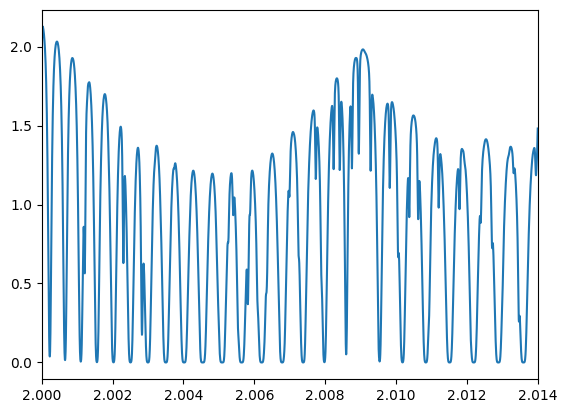

In [66]:
params = [-40.0, 100e-3, 440e-6, 3e-3, 0., 70000.0,0.78]
params_keys = ["delta_t",  "delta_p", "mr_co2", "mr_h2o", "delta_x", "spec_reso","mr_n2"]
params_fixed = [1e-6, 1.511]
params_fixed_keys = ["mr_ch4", "air_mass"]

params_dic = {}
for i, key in enumerate(params_keys):
    params_dic[key] = params[i]

for i, key in enumerate(params_fixed_keys):
    params_dic[key] = params_fixed[i]

flx = calcModel(params_dic)

#plt.plot(spec_data.wavelength, spec_data.flux)
plt.plot(nc.c/atmosphere.freq/1e-4, flx)
plt.xlim(2, 2.014)
# 4.06248278e+00  7.02650324e-02  6.07468402e-04 -2.60915092e-07 6.41019761e+04

In [67]:
co2_grid = np.linspace(0.00032,0.00044,20)
print(co2_grid)

[0.00032    0.00032632 0.00033263 0.00033895 0.00034526 0.00035158
 0.00035789 0.00036421 0.00037053 0.00037684 0.00038316 0.00038947
 0.00039579 0.00040211 0.00040842 0.00041474 0.00042105 0.00042737
 0.00043368 0.00044   ]


In [68]:
n2_grid = 0.78+0.00044-np.linspace(0.00032,0.00044,20)
print(n2_grid)

[0.78012    0.78011368 0.78010737 0.78010105 0.78009474 0.78008842
 0.78008211 0.78007579 0.78006947 0.78006316 0.78005684 0.78005053
 0.78004421 0.78003789 0.78003158 0.78002526 0.78001895 0.78001263
 0.78000632 0.78      ]


In [69]:
flux_budget = [[],[],[],[],[],[],[],[],[],[],[],[],[],[],[],[],[],[],[],[]]

for i in range(len(flux_budget)):
    print(i)
    params = [-40.0, 100e-3, co2_grid[i], 3e-3, 0., 70000.0,0.78+0.00044-co2_grid[i]]
    params_keys = ["delta_t",  "delta_p", "mr_co2", "mr_h2o", "delta_x", "spec_reso","mr_n2"]
    params_fixed = [1e-6, 1.511]
    params_fixed_keys = ["mr_ch4", "air_mass"]

    params_dic = {}
    for i, key in enumerate(params_keys):
        params_dic[key] = params[i]

    for i, key in enumerate(params_fixed_keys):
        params_dic[key] = params_fixed[i]
    print(params_dic)
    flx = calcModel(params_dic)
    flx[flx>1]=1
    flux_budget[i].append(flx)
    print(flux_budget[i])
    #plt.plot(spec_data.wavelength, spec_data.flux)
    #plt.plot(spec_data.wavelength, flx)
    #plt.xlim(1.55, 1.65)
    # 4.06248278e+00  7.02650324e-02  6.07468402e-04 -2.60915092e-07 6.41019761e+04

0
{'delta_t': -40.0, 'delta_p': 0.1, 'mr_co2': 0.00032, 'mr_h2o': 0.003, 'delta_x': 0.0, 'spec_reso': 70000.0, 'mr_n2': 0.78012, 'mr_ch4': 1e-06, 'air_mass': 1.511}
[array([1., 1., 1., ..., 1., 1., 1.])]
1
{'delta_t': -40.0, 'delta_p': 0.1, 'mr_co2': 0.0003263157894736842, 'mr_h2o': 0.003, 'delta_x': 0.0, 'spec_reso': 70000.0, 'mr_n2': 0.7801136842105263, 'mr_ch4': 1e-06, 'air_mass': 1.511}
[array([1., 1., 1., ..., 1., 1., 1.]), array([1., 1., 1., ..., 1., 1., 1.])]
2
{'delta_t': -40.0, 'delta_p': 0.1, 'mr_co2': 0.00033263157894736846, 'mr_h2o': 0.003, 'delta_x': 0.0, 'spec_reso': 70000.0, 'mr_n2': 0.7801073684210527, 'mr_ch4': 1e-06, 'air_mass': 1.511}
[array([1., 1., 1., ..., 1., 1., 1.]), array([1., 1., 1., ..., 1., 1., 1.]), array([1., 1., 1., ..., 1., 1., 1.])]
3
{'delta_t': -40.0, 'delta_p': 0.1, 'mr_co2': 0.00033894736842105265, 'mr_h2o': 0.003, 'delta_x': 0.0, 'spec_reso': 70000.0, 'mr_n2': 0.7801010526315789, 'mr_ch4': 1e-06, 'air_mass': 1.511}
[array([1., 1., 1., ..., 1., 1.,

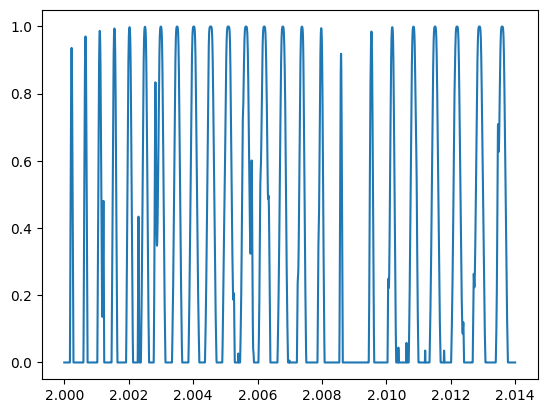

In [70]:
flux_array = np.array(flux_budget[1])
plt.plot(nc.c/atmosphere.freq/1e-4, 1-flux_array[0])

In [71]:
index_forarea = np.where((nc.c/atmosphere.freq/1e-4>2) & (nc.c/atmosphere.freq/1e-4<2.014))[0]

In [72]:
index_forarea[:-1]

array([   1,    2,    3, ..., 6972, 6973, 6974])

In [73]:
area_trans = [[],[],[],[],[],[],[],[],[],[],[],[],[],[],[],[],[],[],[],[]]
for i in range(20):
    area = np.sum((1-flux_array[i][index_forarea[:-1]])*np.diff(nc.c/atmosphere.freq/1e-4)[index_forarea[:-1]])
    area_trans[i].append(area)


Text(0, 0.5, 'area')

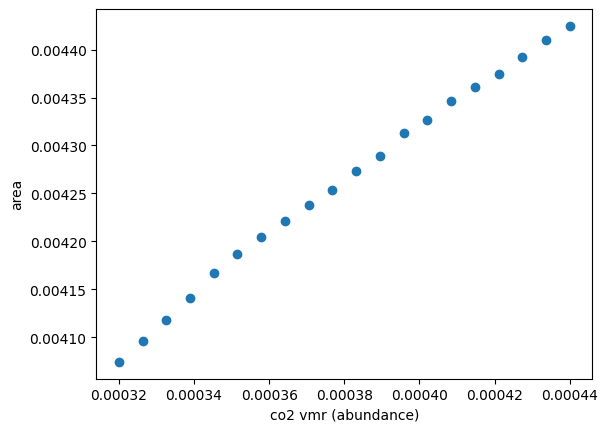

In [74]:
plt.scatter(co2_grid,area_trans)
plt.xlabel('co2 vmr (abundance)')
plt.ylabel('area')

In [75]:
co2_195205 = (area_trans[-1][0]-area_trans[0][0])/(co2_grid[-1]-co2_grid[0])
co2_195205

2.920846127177863